# Еще одна иллюстрация метода ПВД для астероида вблизи точки с большим значением кривизны видимой траеткории

Тест из эфемерид.  Данные — те же 20 положений через 15 минут с ошибкой `POS_ERR`.

Строится corner-plot для $a$, $e$, $i$, $\Omega$, $\omega$, $M$ с наложением элементов MPCORB.

In [1]:
from math import *
import numpy as np

import pandas as pd

import os
import subprocess
from concurrent.futures import ThreadPoolExecutor

from astropy.time import Time

import emcee
import corner
import warnings
from scipy.optimize import least_squares

In [2]:
ASTEPH_DIR = '/Users/ymax/Documents/coding/claude/nea_orb/astEph' # локальная программа astEph с MPCORB.DAT
ASTEPH_RATE_STEP = 300.0    # с - шаг численного дифференцирования для скоростей из astEph
ASTID = '430478'
MU = 2.9591220828411956E-04 # а.е.^3/сут^2 - GM Солнца (как _GMS в astEph, = k^2)
C_AU_DAY = 299792.458*86400/1.495978707E+08 # скорость света, а.е./сут
ARS = 206264.806                          # угл. сек в радиане
EPS_J2000 = np.radians(23.43929111)         # наклон эклиптики J2000 (как в astEph)

N = 20
TRAJ_ORDER_MIN = 3   # минимальная степень полинома видимой траектории (нужна вторая производная)
TRAJ_ORDER_MAX = 3   # максимальная степень полинома видимой траектории
POS_ERR = 0.01
N_CIRCLE = 3         # число ближайших к эпохе наблюдений для соприкасающейся окружности (None - все)
SEED = 42            # зерно для шума эфемериды и для MCMC (для воспроизводимости)
NWALKERS = 48        # число цепей MCMC
NSTEPS = 4000        # длина цепи
BURNIN = 1000        # отбрасываемые шаги
N_ARC = 6            # число точек для локальной квадратичной подгонки длины дуги
DELTA_T = 15.0


t = Time('2026-11-10T20:00:00.00', format='isot')
JD = float(t.copy(format='jd').value)+DELTA_T*np.arange(N)/1440.0
JD

array([2461355.33333333, 2461355.34375   , 2461355.35416667,
       2461355.36458333, 2461355.375     , 2461355.38541667,
       2461355.39583333, 2461355.40625   , 2461355.41666667,
       2461355.42708333, 2461355.4375    , 2461355.44791667,
       2461355.45833333, 2461355.46875   , 2461355.47916667,
       2461355.48958333, 2461355.5       , 2461355.51041667,
       2461355.52083333, 2461355.53125   ])

In [3]:
def _run_asteph(target, jd, location):
    """Один вызов astEph: (RA, DEC в градусах, V) на момент jd (UTC) для обсерватории location."""
    exe = os.path.join(ASTEPH_DIR, 'astEph')
    out = subprocess.run([exe, str(target), f'{jd:.8f}', f'obscode={location}'], cwd=ASTEPH_DIR,
                         capture_output=True, text=True, timeout=120)
    if out.returncode != 0:
        raise RuntimeError(f'astEph: {out.stderr.strip() or out.stdout.strip()}')
    val = {l.split('=')[0].strip(): l.split('=', 1)[1].split()[0] for l in out.stdout.splitlines() if '=' in l}
    return np.degrees(float(val['RA'])), np.degrees(float(val['DEC'])), float(val['Vmag'])

def get_asteph_ephemeris(target, JD, location, err=0.005):
    """Та же эфемерида, что get_horizons_ephemeris, но из локальной программы astEph (ASTEPH_DIR).
    astEph дает только положение и V, поэтому скорости считаются по положениям в моменты
    jd -+ ASTEPH_RATE_STEP (с), а DELTA не заполняется. Первый вызов делается отдельно: при новой
    эпохе MPCORB.DAT astEph сначала считает и сохраняет свой кэш интегрирования (~10 с). Остальные
    вызовы идут параллельно.
    err - стандартная ошибка положения (arcsec): к RA*cos(DEC) и DEC каждого эфемеридного положения
    добавляется независимый гауссов шум N(0, err). err=0 - без шума."""
    JD = np.atleast_1d(np.asarray(JD, dtype=float))
    if not os.path.isfile(os.path.join(ASTEPH_DIR, 'astEph')):
        raise FileNotFoundError(f'нет программы {ASTEPH_DIR}/astEph (сборка: cc -O2 -o astEph astEph.c -lm)')
    h = ASTEPH_RATE_STEP/86400
    jds = np.concatenate([JD, JD-h, JD+h])
    first = _run_asteph(target, jds[0], location)
    with ThreadPoolExecutor(max_workers=8) as ex:
        rest = list(ex.map(lambda jd: _run_asteph(target, jd, location), jds[1:]))
    res = np.array([first] + rest).reshape(3, len(JD), 3)
    (ra, dec, v), (ra1, dec1, _), (ra2, dec2, _) = [res[k].T for k in range(3)]
    dra = ((ra2-ra1+180) % 360 - 180)*np.cos(np.radians(dec))*3600/(2*ASTEPH_RATE_STEP/3600)
    ddec = (dec2-dec1)*3600/(2*ASTEPH_RATE_STEP/3600)
    if err > 0:
        ra = (ra + np.random.normal(0, err, len(JD))/3600/np.cos(np.radians(dec))) % 360
        dec = dec + np.random.normal(0, err, len(JD))/3600
    return pd.DataFrame(dict(JD=JD, RA_EPH=ra, DEC_EPH=dec, dRAcosD=dra, dDEC=ddec, # arcsec/hour
                             VMAG=v, DELTA=np.nan))


def get_observer_state(JD, location='217', asteph_dir=ASTEPH_DIR):
    """Гелиоцентрические положение R (а.е.), скорость V (а.е./сут) и ускорение A (а.е./сут^2)
    наблюдателя в обсерватории с кодом MPC location на момент JD (UTC), экваториальная система J2000.
    Считает программа astEph (режим --observer). Возвращает три numpy-массива по 3 компоненты."""
    out = subprocess.run([os.path.join(asteph_dir, 'astEph'), '--observer', f'{float(JD):.8f}',
                          f'obscode={location}'], cwd=asteph_dir, capture_output=True, text=True, timeout=300)
    if out.returncode != 0:
        raise RuntimeError(f'astEph: {out.stderr.strip() or out.stdout.strip()}')
    val = {k.strip(): v for k, v in (l.split('=', 1) for l in out.stdout.splitlines() if '=' in l)}
    R, V, A = (np.array(val[k].split(), dtype=float) for k in ('R', 'V', 'A'))
    return R, V, A

### Параметры видимого движения из видимой траектории

Точка проекции — средние экваториальные координаты $(\alpha_0,\delta_0)=(\overline{\alpha},\overline{\delta})$.
Наблюдения пересчитываются в тангенциальные (гономонические) координаты

$$\xi=\frac{\cos\delta\sin(\alpha-\alpha_0)}{\sin\delta\sin\delta_0+\cos\delta\cos\delta_0\cos(\alpha-\alpha_0)},\qquad
\eta=\frac{\sin\delta\cos\delta_0-\cos\delta\sin\delta_0\cos(\alpha-\alpha_0)}{\sin\delta\sin\delta_0+\cos\delta\cos\delta_0\cos(\alpha-\alpha_0)} .$$

В локальном базисе $\mathbf e_1=(-\sin\alpha_0,\cos\alpha_0,0)$,
$\mathbf e_2=(-\cos\alpha_0\sin\delta_0,-\sin\alpha_0\sin\delta_0,\cos\delta_0)$,
$\mathbf e_3=\mathbf D(\alpha_0,\delta_0)$

$$\mathbf D=\frac{\xi\,\mathbf e_1+\eta\,\mathbf e_2+\mathbf e_3}{\sqrt{1+\xi^2+\eta^2}} .$$

Видимая траектория в плоскости $(\xi,\eta)$ — плоская кривая $\xi(t),\eta(t)$; в момент $t_0$
(средний момент наблюдений) скорость вдоль неё, направление касательной, кривизна и скорость
изменения скорости равны

$$\mu=\sqrt{\dot\xi^2+\dot\eta^2},\qquad
\mu\sin\tilde\psi=\dot\xi,\qquad \mu\cos\tilde\psi=\dot\eta,$$
$$\varkappa=\frac{\dot\xi\,\ddot\eta-\dot\eta\,\ddot\xi}{\mu^3},\qquad
\mu\dot\mu=\dot\xi\,\ddot\xi+\dot\eta\,\ddot\eta .$$

Это и есть величины, входящие в уравнения ПВД: в начале координат ($\xi=\eta=0$)

$$\dot{\mathbf D}=\dot\xi\,\mathbf e_1+\dot\eta\,\mathbf e_2,\qquad
\ddot{\mathbf D}=\ddot\xi\,\mathbf e_1+\ddot\eta\,\mathbf e_2-\mu^2\,\mathbf e_3,$$

откуда $\mu=|\dot{\mathbf D}|$, $\mu^3\varkappa=(\mathbf D\,\dot{\mathbf D}\,\ddot{\mathbf D})$,
$\mu\dot\mu=\dot{\mathbf D}\cdot\ddot{\mathbf D}$. Гномоническая проекция не изометрия, поэтому
на расстоянии от начала координат эти равенства выполняются приближённо; так как точка проекции —
средние координаты, положение на эпохе смещено на $(\xi_0,\eta_0)$ и поправки к $\mu,\varkappa$
имеют порядок $\xi_0^2+\eta_0^2$ (здесь $\sim10^{-10}$). Вектор $\mathbf D$ и позиционный угол
$\psi$ в локальном базисе (восток — север) пересчитываются в положение на эпохе точно.

Степень полинома для $\xi$ и $\eta$ подбирается независимо: берётся наименьшая степень $n$
(`TRAJ_ORDER_MIN`…`TRAJ_ORDER_MAX`), при которой невязки согласуются с ошибкой положения
`POS_ERR`, то есть $\chi^2/\mathrm{dof}\le 1+2\sqrt{2/\mathrm{dof}}$ (если такой степени нет —
степень с наилучшим достижимым $\chi^2/\mathrm{dof}$). Аппроксимация берётся **одной степени для
обеих координат** — максимальной из двух, как при подгонке вектора $\mathbf D$ в `AMP_test.ipynb`:
$\mu\dot\mu=\dot\xi\ddot\xi+\dot\eta\ddot\eta$ есть почти компенсация $\xi$- и $\eta$-вкладов,
и при разных порядках их ошибки не сокращаются (пара $(4,3)$ даёт неверную орбиту при любом шуме).

In [4]:
def tangFromRADE(ra, dec, RA, DEC):
    """Тангенциальные (гономонические) координаты точки (ra, dec) относительно опорной
    точки (RA, DEC); все углы в радианах."""
    den = np.sin(dec)*np.sin(DEC) + np.cos(dec)*np.cos(DEC)*np.cos(ra-RA)
    ksi = np.cos(dec)*np.sin(ra-RA)/den
    eta = (np.sin(dec)*np.cos(DEC) - np.cos(dec)*np.sin(DEC)*np.cos(ra-RA))/den
    return ksi, eta

def RADecFromTang(ksi, eta, RA, Dec):
    """Обратное преобразование: тангенциальные координаты (ksi, eta) -> (ra, dec), рад."""
    x, y, z = np.dot(np.array([[-np.sin(RA), -np.cos(RA)*np.sin(Dec),  np.cos(RA)*np.cos(Dec)],
                               [ np.cos(RA), -np.sin(RA)*np.sin(Dec),  np.sin(RA)*np.cos(Dec)],
                               [ 0,          np.cos(Dec),              np.sin(Dec)]]),
                     np.array([ksi, eta, 1]))/np.sqrt(1 + ksi*ksi + eta*eta)
    ra = np.arctan2(y, x)
    dec = np.arctan2(z, np.sqrt(x*x + y*y))
    if ra < 0:
        ra += 2*np.pi
    return ra, dec

In [5]:
def _polyfit(x, y, n):
    """МНК-полином степени n: коэффициенты и аппроксимированные значения в точках x."""
    X = np.column_stack([x**k for k in range(n+1)])
    C = np.linalg.lstsq(X, y, rcond=None)[0]
    return C, X @ C

def _chi2_dof(x, y, n, err):
    """chi^2/dof невязок полинома степени n при ошибке положения err (угл. сек)."""
    r = y - _polyfit(x, y, n)[1]
    return (r @ r)/((err/ARS)**2*(len(x) - n - 1))

def choose_poly_order(x, y, err=POS_ERR, n_min=TRAJ_ORDER_MIN, n_max=TRAJ_ORDER_MAX):
    """Наименьшая степень полинома, при которой невязки согласуются с ошибкой err:
    chi^2/dof <= 1 + 2*sqrt(2/dof) (отклонение chi^2 на 2 sigma при данном числе степеней свободы).
    Если такой степени нет (реализация шума вышла больше err), порог ослабляется до наилучшего
    достижимого chi^2/dof с запасом 5 %. При err = 0 (нет шума) возвращается n_max."""
    if err <= 0:
        return n_max
    ns = list(range(n_min, min(n_max, N - 2) + 1))
    chi = [_chi2_dof(x, y, n, err) for n in ns]
    lim = 1.05*min(chi)
    for n, c in zip(ns, chi):
        if c <= max(1 + 2*np.sqrt(2/(N - n - 1)), lim):
            return n
    return ns[-1]

def analyze_apparent_trajectory(pos, n_min=TRAJ_ORDER_MIN, n_max=TRAJ_ORDER_MAX, err=POS_ERR):
    """Видимая траектория в тангенциальных координатах.

    Точка проекции - средние экваториальные координаты: RA0 = mean(RA), Dec0 = mean(Dec).
    Координаты ksi(t), eta(t), t = JD - JD0 (JD0 - средний момент наблюдений), аппроксимируются
    полиномами МНК одной степени для обеих координат; степень - наименьшая, при которой невязки
    обеих координат согласуются с ошибкой положения err (единая степень нужна потому, что
    mu_dot - почти компенсация ksi- и eta-вкладов). Возвращаются производные в t = 0.

    Возвращает dict: jd0, RA0, Dec0, n_ksi, n_eta, коэффициенты полиномов, ksi0, eta0
    (положение на эпохе, рад), ksi1, eta1 (рад/сут), ksi2, eta2 (рад/сут^2), СКО невязок
    rms_ksi, rms_eta (рад) и таблицу diag (rms и chi^2/dof для разных степеней)."""
    if n_max < 2:
        raise ValueError('для кривизны нужен порядок полинома n >= 2')
    jd0 = pos['JD'].mean()
    RA0 = np.radians(pos['RA_EPH'].values).mean()
    Dec0 = np.radians(pos['DEC_EPH'].values).mean()
    x = pos['JD'].values - jd0
    ksi, eta = tangFromRADE(np.radians(pos['RA_EPH'].values), np.radians(pos['DEC_EPH'].values),
                            RA0, Dec0)

    # степени для ksi и eta подбираются независимо, но аппроксимация берется ОДНОЙ степени
    # (как при подгонке вектора D в AMP_test.ipynb): mu_dot = (ksi' ksi'' + eta' eta'')/mu -
    # почти компенсация вкладов ksi и eta, и при разных порядках ошибки не сокращаются
    n = max(choose_poly_order(x, ksi, err, n_min, n_max),
            choose_poly_order(x, eta, err, n_min, n_max))
    n_ksi = n_eta = n
    Cx, fit_ksi = _polyfit(x, ksi, n)
    Cy, fit_eta = _polyfit(x, eta, n)

    diag = pd.DataFrame([dict(n=n,
                              rms_ksi=np.std(ksi - _polyfit(x, ksi, n)[1])*ARS,
                              chi2_ksi=_chi2_dof(x, ksi, n, err),
                              rms_eta=np.std(eta - _polyfit(x, eta, n)[1])*ARS,
                              chi2_eta=_chi2_dof(x, eta, n, err))
                         for n in range(n_min, n_max+1)])
    return dict(jd0=jd0, RA0=RA0, Dec0=Dec0, n_ksi=n_ksi, n_eta=n_eta, coef_ksi=Cx, coef_eta=Cy,
                ksi0=Cx[0], eta0=Cy[0], ksi1=Cx[1], eta1=Cy[1], ksi2=2*Cx[2], eta2=2*Cy[2],
                rms_ksi=np.std(ksi - fit_ksi), rms_eta=np.std(eta - fit_eta), diag=diag)


In [6]:
def poly_val(C, x):
    """Значение полинома (коэффициенты C по возрастанию степени) в точках x."""
    return np.polyval(np.array(C, float)[::-1], x)

def poly_deriv(C, x, k):
    """k-я производная полинома (коэффициенты C по возрастанию степени) в точках x."""
    c = np.array(C, float)
    for _ in range(k):
        c = c[1:]*np.arange(1, len(c))
    return np.polyval(c[::-1], x) if len(c) else np.zeros_like(np.asarray(x, float))

def apparent_motion_parameters(traj, t=0.0):
    """Параметры видимого движения в момент t = JD - JD0 (сут):

        mu = sqrt(ksi'^2 + eta'^2),  mu sin(psi~) = ksi',  mu cos(psi~) = eta',
        varkappa = (ksi' eta'' - eta' ksi'')/mu^3,  mu_dot = (ksi' ksi'' + eta' eta'')/mu.

    Значения ksi, eta и их производные берутся в момент t из полиномиальной аппроксимации.
    Возвращает mu (рад/сут), psi (рад), varkappa (1/рад), dot_mu (рад/сут^2) и векторы
    D, T, M = D x T (правая тройка) в экваториальной системе J2000.

    Точка проекции - средние координаты, поэтому положение на эпохе (ksi0, eta0) не совпадает
    с началом координат: D (направление на объект) и psi (позиционный угол в локальном базисе
    восток - север) пересчитываются в это положение точно, через производную единичного вектора
        D' = (ksi' e1 + eta' e2 - D (ksi0 ksi' + eta0 eta')/|P|)/|P|,  |P| = sqrt(1+ksi0^2+eta0^2)."""
    x0, y0 = poly_val(traj['coef_ksi'], t), poly_val(traj['coef_eta'], t)
    x1, y1 = poly_deriv(traj['coef_ksi'], t, 1), poly_deriv(traj['coef_eta'], t, 1)
    x2, y2 = poly_deriv(traj['coef_ksi'], t, 2), poly_deriv(traj['coef_eta'], t, 2)
    a0, d0 = traj['RA0'], traj['Dec0']                  # точка проекции
    rho = np.sqrt(1 + x0*x0 + y0*y0)
    mu = np.hypot(x1, y1)
    varkappa = (x1*y2 - y1*x2)/mu**3
    dot_mu = (x1*x2 + y1*y2)/mu
    ra, dec = RADecFromTang(x0, y0, a0, d0)             # положение на эпохе t
    D = np.array([np.cos(ra)*np.cos(dec), np.sin(ra)*np.cos(dec), np.sin(dec)])
    eE = np.array([-np.sin(ra), np.cos(ra), 0.0])                                   # восток
    eN = np.array([-np.cos(ra)*np.sin(dec), -np.sin(ra)*np.sin(dec), np.cos(dec)])  # север
    e1 = np.array([-np.sin(a0), np.cos(a0), 0.0])                                   # оси проекции
    e2 = np.array([-np.cos(a0)*np.sin(d0), -np.sin(a0)*np.sin(d0), np.cos(d0)])
    T = x1*e1 + y1*e2 - D*(x0*x1 + y0*y1)/rho           # направление видимого движения
    T = T/np.linalg.norm(T)
    psi = np.arctan2(T @ eE, T @ eN)
    return dict(mu=mu, psi=psi, varkappa=varkappa, dot_mu=dot_mu, D=D, T=T, M=np.cross(D, T))


### Точка максимальной кривизны и контроль тождества

**Эпоха.** Кривизна видимой траектории сильно меняется вдоль дуги, поэтому точку касания
соприкасающейся окружности естественно брать там, где она максимальна:
$t^*=\arg\max_t|\varkappa(t)|$. В этой точке $\dot\varkappa=0$: кривизна стационарна и слабее
всего зависит от ошибки в выборе точки касания.

**Степень полинома** выбирается по невязкам (наименьшая общая для $\xi$ и $\eta$ степень, при
которой они согласуются с `POS_ERR`) — это устойчивее, чем критерии по вторичным величинам.

**Контроль тождества.** Кривизна в $t^*$ вычисляется из полиномиальной аппроксимации

$$\varkappa_{id}=\frac{\dot\xi\,\ddot\eta-\dot\eta\,\ddot\xi}{\mu^3}$$

и сравнивается с независимой геометрической оценкой — соприкасающейся окружностью в $t^*$
(касательная $\mathbf u=(\sin\psi,\cos\psi)$, центр на нормали $\mathbf n=(-\cos\psi,\sin\psi)$
на расстоянии $t=1/\varkappa$, МНК по `N_CIRCLE` ближайшим точкам):

$$\varkappa_{circ}=\frac{2\sum_i(\Delta_i\cdot\mathbf n)^2}{\sum_i|\Delta_i|^2(\Delta_i\cdot\mathbf n)} .$$

Согласие этих двух оценок и есть контроль: если вторая производная полинома описывает реальную
кривизну видимой траектории, а не шум, то $\varkappa_{id}$ и $\varkappa_{circ}$ должны совпадать
в пределах ошибок. Таблица ниже даёт расхождение для всех допустимых степеней: сама окружность
смещена (даже локально траектория не круговая), поэтому расхождение не равно нулю и составляет
несколько процентов; при заведомо недостаточной степени оно, наоборот, бывает обманчиво малым —
поэтому степень по нему и не выбирается.

In [7]:
def max_curvature_epoch(traj, jd_min, jd_max, n_grid=801):
    """Момент t* максимальной по модулю кривизны видимой траектории (по полиномиальной модели)."""
    t = np.linspace(jd_min - traj['jd0'], jd_max - traj['jd0'], n_grid)
    k1, e1 = poly_deriv(traj['coef_ksi'], t, 1), poly_deriv(traj['coef_eta'], t, 1)
    k2, e2 = poly_deriv(traj['coef_ksi'], t, 2), poly_deriv(traj['coef_eta'], t, 2)
    kap = (k1*e2 - e1*k2)/np.hypot(k1, e1)**3
    return t[np.argmax(np.abs(kap))]

def osculating_circle_curvature(pos, traj, t_ep, psi, n_circle=N_CIRCLE):
    """Кривизна в момент t_ep по соприкасающейся окружности.

    Окружность проходит через P0 = (ksi(t_ep), eta(t_ep)) и касается траектории в этой точке;
    касательная u = (sin psi, cos psi). Центр - на нормали n = (-cos psi, sin psi) на расстоянии
    t = 1/varkappa. Для Delta_i = P_i - P0: |Delta_i|^2 = 2 t (Delta_i . n), МНК по n_circle
    ближайшим к t_ep наблюдениям (None - все):
        t = sum |Delta_i|^2 (Delta_i.n) / (2 sum (Delta_i.n)^2),   varkappa = 1/t."""
    ksi, eta = tangFromRADE(np.radians(pos['RA_EPH'].values), np.radians(pos['DEC_EPH'].values),
                            traj['RA0'], traj['Dec0'])
    if n_circle is not None:
        m = np.argsort(np.abs(pos['JD'].values - traj['jd0'] - t_ep))[:n_circle]
        ksi, eta = ksi[m], eta[m]
    nrm = np.array([-np.cos(psi), np.sin(psi)])        # единичная нормаль к касательной
    dx = ksi - poly_val(traj['coef_ksi'], t_ep)
    dy = eta - poly_val(traj['coef_eta'], t_ep)
    dn = dx*nrm[0] + dy*nrm[1]
    t_ = (dx*dx + dy*dy) @ dn/(2*(dn @ dn))
    return 1/t_

def curvature_identity_table(pos, ns=range(TRAJ_ORDER_MIN, TRAJ_ORDER_MAX + 1), n_circle=N_CIRCLE):
    """Таблица согласия тождества и соприкасающейся окружности в точке максимума |varkappa|.

    Для каждой степени n подгоняются ksi(t), eta(t) одной степени n, находится t*(n) и
    сравниваются varkappa_id = (ksi' eta'' - eta' ksi'')/mu^3 и varkappa_circ по окружности."""
    jd0 = analyze_apparent_trajectory(pos)['jd0']
    x = pos['JD'].values - jd0
    ksi, eta = tangFromRADE(np.radians(pos['RA_EPH'].values), np.radians(pos['DEC_EPH'].values),
                            analyze_apparent_trajectory(pos)['RA0'],
                            analyze_apparent_trajectory(pos)['Dec0'])
    rows = []
    for n in ns:
        tr = analyze_apparent_trajectory(pos, n_min=n, n_max=n)
        t_ep = max_curvature_epoch(tr, pos['JD'].min(), pos['JD'].max())
        mo = apparent_motion_parameters(tr, t_ep)
        kc = osculating_circle_curvature(pos, tr, t_ep, mo['psi'], n_circle)
        chi2 = max(_chi2_dof(x, ksi, n, POS_ERR), _chi2_dof(x, eta, n, POS_ERR))
        rows.append(dict(n=n, t_ep_min=t_ep*1440, kappa_id=mo['varkappa'], kappa_circle=kc,
                         delta=abs(kc/mo['varkappa'] - 1), chi2_max=chi2))
    return pd.DataFrame(rows)


In [8]:
np.random.seed(SEED)                     # фиксируем шум эфемериды - MCMC должен быть воспроизводим
pos = get_asteph_ephemeris(ASTID, JD, '217',err=POS_ERR)
pos

,JD,RA_EPH,DEC_EPH,dRAcosD,dDEC,VMAG,DELTA
0,2.461355e+06,22.418993,27.164386,-1.792615,4.060315,17.76,NaN
1,2.461355e+06,22.418860,27.164660,-1.573793,3.967631,17.76,NaN
2,2.461355e+06,22.418748,27.164933,-1.343021,3.881267,17.76,NaN
3,2.461355e+06,22.418655,27.165195,-1.101216,3.801553,17.76,NaN
4,2.461355e+06,22.418574,27.165459,-0.849356,3.728804,17.76,NaN
5,2.461355e+06,22.418518,27.165718,-0.588461,3.663323,17.76,NaN
6,2.461355e+06,22.418488,27.165967,-0.319583,3.605349,17.76,NaN
7,2.461355e+06,22.418471,27.166219,-0.043814,3.555105,17.76,NaN
8,2.461355e+06,22.418475,27.166462,0.237727,3.512796,17.76,NaN
9,2.461355e+06,22.418508,27.166706,0.523896,3.478561,17.76,NaN


In [9]:
traj = analyze_apparent_trajectory(pos)               # степень по невязкам, общая для ksi и eta
n_star = traj['n_ksi']
t_ep = max_curvature_epoch(traj, pos['JD'].min(), pos['JD'].max())    # точка максимума |varkappa|
motion = apparent_motion_parameters(traj, t_ep)                        # D, T, psi, mu, mu_dot, varkappa
k_circ = osculating_circle_curvature(pos, traj, t_ep, motion['psi'])   # независимая оценка кривизны
print(f'JD0 = {traj["jd0"]:.5f}; точка максимума |varkappa|: t* = {t_ep*1440:+.1f} мин '
      f'(JD {traj["jd0"] + t_ep:.5f})')
print(f'точка проекции (средние координаты) RA = {np.degrees(traj["RA0"]):.6f}°, '
      f'Dec = {np.degrees(traj["Dec0"]):.6f}°')
print(f'степень полинома (общая для ksi и eta): n = {n_star}; '
      f'СКО невязок {traj["rms_ksi"]*ARS:.3f}″ и {traj["rms_eta"]*ARS:.3f}″ при POS_ERR = {POS_ERR}″')
print(f'контроль тождества в t*: varkappa_id = {motion["varkappa"]:.0f} 1/рад, '
      f'varkappa_circ = {k_circ:.0f} 1/рад, расхождение {100*abs(k_circ/motion["varkappa"] - 1):+.2f}%')
display(pd.Series({'μ, рад/сут': motion['mu'], 'μ, "/час': motion['mu']*ARS/24,
                   'ψ, °': np.degrees(motion['psi']),
                   'ϰ (тождество), 1/рад': motion['varkappa'],
                   'R = 1/|ϰ|, ″': ARS/abs(motion['varkappa']),
                   'μ̇, рад/сут²': motion['dot_mu']}))
crit = curvature_identity_table(pos)          # расхождение тождества и окружности по степеням
crit.assign(delta_pct=100*crit['delta'])[['n', 't_ep_min', 'kappa_id', 'kappa_circle', 'delta_pct', 'chi2_max']].round(2)

JD0 = 2461355.43229; точка максимума |varkappa|: t* = -9.3 мин (JD 2461355.42586)
точка проекции (средние координаты) RA = 22.418897°, Dec = 27.166797°
степень полинома (общая для ksi и eta): n = 3; СКО невязок 0.012″ и 0.009″ при POS_ERR = 0.01″
контроль тождества в t*: varkappa_id = -18711 1/рад, varkappa_circ = -12952 1/рад, расхождение +30.78%


μ, рад/сут                  0.000409
μ, "/час                    3.519092
ψ, °                        7.969327
ϰ (тождество), 1/рад   -18710.651593
R = 1/|ϰ|, ″               11.023924
μ̇, рад/сут²                0.000099
dtype: float64

,n,t_ep_min,kappa_id,kappa_circle,delta_pct,chi2_max
0,3,-9.26,-18710.65,-12952.16,30.78,1.75


сохранено: AMP_apparent_curvature5_traj.png


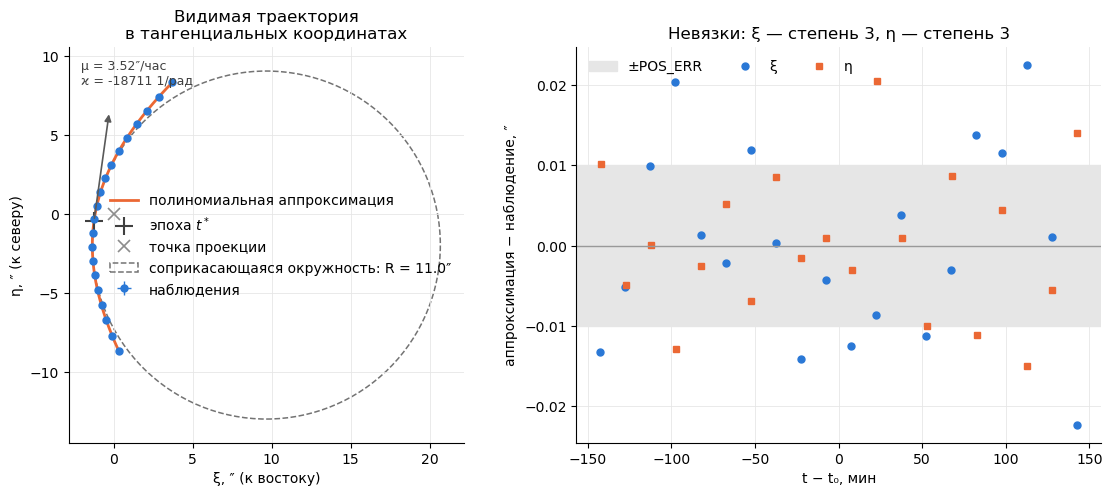

In [10]:
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    pass  # запуск как обычный .py-скрипт
import matplotlib.pyplot as plt
SERIES_COLORS = ['#2a78d6', '#eb6834'] # 1-й и 2-й цвета проверенной категориальной палитры

TRAJ_PNG = 'AMP_apparent_curvature5_traj.png' # файл с графиком видимой траектории

# наблюденная видимая траектория и ее полиномиальная аппроксимация в тангенциальных координатах
ksi_obs, eta_obs = tangFromRADE(np.radians(pos['RA_EPH'].values), np.radians(pos['DEC_EPH'].values),
                                traj['RA0'], traj['Dec0'])
t_min = (pos['JD'].values - traj['jd0'])*1440
x_ep, y_ep = poly_val(traj['coef_ksi'], t_ep)*ARS, poly_val(traj['coef_eta'], t_ep)*ARS
design = lambda t, n: np.column_stack([(t/1440)**k for k in range(n+1)])
tt = np.linspace(t_min.min(), t_min.max(), 400)
ksi_fit = design(tt, traj['n_ksi']) @ traj['coef_ksi']
eta_fit = design(tt, traj['n_eta']) @ traj['coef_eta']
res_ksi = (ksi_obs - design(t_min, traj['n_ksi']) @ traj['coef_ksi'])*ARS
res_eta = (eta_obs - design(t_min, traj['n_eta']) @ traj['coef_eta'])*ARS

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw=dict(width_ratios=[0.85, 1]))

# (а) видимая траектория
ax1.errorbar(ksi_obs*ARS, eta_obs*ARS, xerr=POS_ERR, yerr=POS_ERR, fmt='o', color=SERIES_COLORS[0],
             ms=5, lw=1, capsize=0, label='наблюдения')
ax1.plot(ksi_fit*ARS, eta_fit*ARS, '-', color=SERIES_COLORS[1], lw=2,
         label='полиномиальная аппроксимация')
ax1.plot(x_ep, y_ep, ls='none', marker='+', color='0.25', ms=13, mew=1.5, label='эпоха $t^*$')
ax1.plot(0, 0, ls='none', marker='x', color='0.55', ms=8, mew=1.2, label='точка проекции')
# касательная к траектории на эпохе t0 - направление видимого движения
L = 7.0
tx, ty = poly_deriv(traj['coef_ksi'], t_ep, 1), poly_deriv(traj['coef_eta'], t_ep, 1)
tx, ty = L*tx/np.hypot(tx, ty), L*ty/np.hypot(tx, ty)
ax1.annotate('', xy=(x_ep + tx, y_ep + ty), xytext=(x_ep, y_ep),
             arrowprops=dict(arrowstyle='-|>', color='0.35', lw=1.2))
# соприкасающаяся окружность: R = 1/|varkappa|, центр - на нормали к касательной в t0
Rc = ARS/abs(motion['varkappa'])
tc = ARS/motion['varkappa']                     # знаковый радиус, рад -> угл. сек
cx, cy = x_ep - tc*np.cos(motion['psi']), y_ep + tc*np.sin(motion['psi'])
span = max(np.ptp(ksi_obs*ARS), np.ptp(eta_obs*ARS))
xs, ys = ksi_obs*ARS, eta_obs*ARS
if Rc < 3*span:                                  # окружность видна - учитываем её в пределах осей
    ax1.add_patch(plt.Circle((cx, cy), Rc, fill=False, ls='--', lw=1.1, color='0.45',
                             label=f'соприкасающаяся окружность: R = {Rc:.1f}″'))
    xs, ys = np.append(xs, [cx - Rc, cx + Rc]), np.append(ys, [cy - Rc, cy + Rc])
mid = 0.5*np.array([xs.min() + xs.max(), ys.min() + ys.max()])
half = 0.5*max(np.ptp(xs), np.ptp(ys)) + 1.5
ax1.set_xlim(mid[0] - half, mid[0] + half)
ax1.set_ylim(mid[1] - half, mid[1] + half)
ax1.set_xlabel('ξ, ″ (к востоку)')
ax1.set_ylabel('η, ″ (к северу)')
ax1.set_title('Видимая траектория\nв тангенциальных координатах')
ax1.set_aspect('equal', adjustable='box')
ax1.legend(frameon=False, loc='best')
ax1.grid(True, color='0.9', lw=0.6)
ax1.text(0.03, 0.97, f'μ = {motion["mu"]*ARS/24:.2f}″/час\nϰ = {motion["varkappa"]:.0f} 1/рад',
         transform=ax1.transAxes, va='top', fontsize=9, color='0.25')

# (б) невязки аппроксимации - контроль качества полинома
ax2.axhspan(-POS_ERR, POS_ERR, color='0.9', zorder=0, label='±POS_ERR')
ax2.plot(t_min, res_ksi, 'o', color=SERIES_COLORS[0], ms=5, label='ξ')
ax2.plot(t_min+0.3, res_eta, 's', color=SERIES_COLORS[1], ms=5, label='η')
ax2.axhline(0, color='0.6', lw=1)
ax2.set_xlabel('t − t₀, мин')
ax2.set_ylabel('аппроксимация − наблюдение, ″')
ax2.set_title(f'Невязки: ξ — степень {traj["n_ksi"]}, η — степень {traj["n_eta"]}')
ax2.legend(frameon=False, ncol=3, loc='best')
ax2.grid(True, color='0.9', lw=0.6)
for a in (ax1, ax2):
    for sp in ('top', 'right'):
        a.spines[sp].set_visible(False)
plt.tight_layout()
fig.savefig(TRAJ_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', TRAJ_PNG)
plt.show()

сохранено: AMP_apparent_curvature5_delta.png


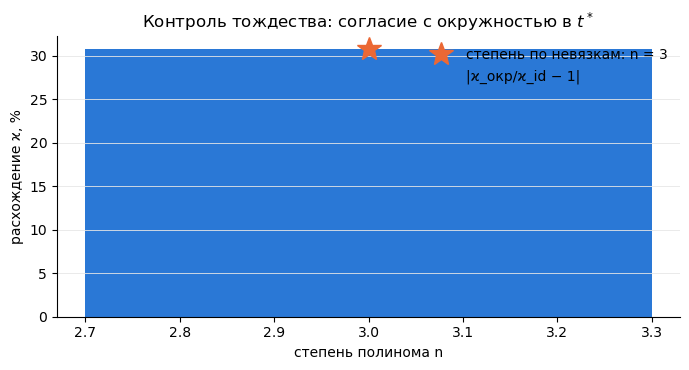

In [11]:
fig, ax = plt.subplots(figsize=(7.0, 3.8))
DELTA_PNG = 'AMP_apparent_curvature5_delta.png'

ax.bar(crit['n'], 100*crit['delta'], color=SERIES_COLORS[0], width=0.6, label='|ϰ_окр/ϰ_id − 1|')
ax.plot(n_star, 100*crit.loc[crit['n'] == n_star, 'delta'].values[0], '*', color=SERIES_COLORS[1],
        ms=18, label=f'степень по невязкам: n = {n_star}')
ax.set_xlabel('степень полинома n')
ax.set_ylabel('расхождение ϰ, %')
ax.set_title('Контроль тождества: согласие с окружностью в $t^*$')
ax.grid(True, axis='y', color='0.9', lw=0.6)
ax.legend(frameon=False)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
fig.savefig(DELTA_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', DELTA_PNG)
plt.show()


сохранено: AMP_apparent_curvature5_kappa.png


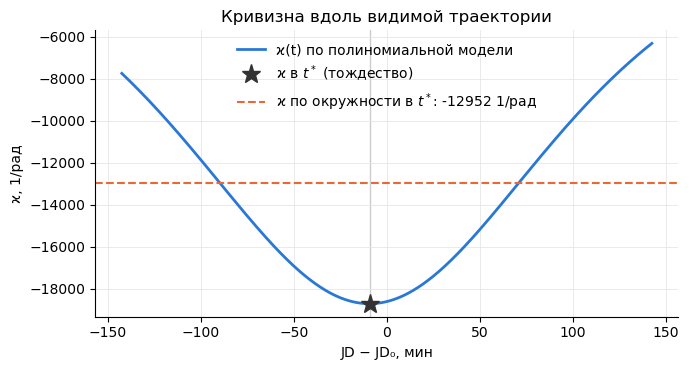

In [12]:
fig, ax = plt.subplots(figsize=(7.0, 3.8))
KAPPA_PNG = 'AMP_apparent_curvature5_kappa.png'

t_all = (pos['JD'].values - traj['jd0'])*1440
tt = np.linspace(t_all.min(), t_all.max(), 400)
x_d = tt/1440
k1, e1_ = poly_deriv(traj['coef_ksi'], x_d, 1), poly_deriv(traj['coef_eta'], x_d, 1)
k2, e2_ = poly_deriv(traj['coef_ksi'], x_d, 2), poly_deriv(traj['coef_eta'], x_d, 2)
kap_t = (k1*e2_ - e1_*k2)/np.hypot(k1, e1_)**3
k_circ = osculating_circle_curvature(pos, traj, t_ep, motion['psi'])

ax.plot(tt, kap_t, color=SERIES_COLORS[0], lw=2, label='ϰ(t) по полиномиальной модели')
ax.plot(t_ep*1440, motion['varkappa'], '*', color='0.2', ms=14, label='ϰ в $t^*$ (тождество)')
ax.axhline(k_circ, color=SERIES_COLORS[1], ls='--', lw=1.5,
           label=f'ϰ по окружности в $t^*$: {k_circ:.0f} 1/рад')
ax.axvline(t_ep*1440, color='0.8', lw=1, zorder=0)
ax.set_xlabel('JD − JD₀, мин')
ax.set_ylabel('ϰ, 1/рад')
ax.set_title('Кривизна вдоль видимой траектории')
ax.grid(True, color='0.9', lw=0.6)
ax.legend(frameon=False, loc='best')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
fig.savefig(KAPPA_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', KAPPA_PNG)
plt.show()


In [13]:
g, dot_g, ddot_g = get_observer_state(traj['jd0'] + t_ep, location='217', asteph_dir=ASTEPH_DIR)
g, dot_g, ddot_g

(array([0.66056215, 0.67691555, 0.29344365]),
 array([-0.01329551,  0.01043584,  0.00454028]),
 array([ 3.21180426e-05, -1.42077177e-03, -9.07041177e-05]))

### Основные уравнения метода ПВД и необходимые соотношения

Величины $\mu$, $\psi$, $\varkappa$ и $\dot\mu$ берутся из видимой траектории (раздел выше),
$\mathbf D = \mathbf D(\alpha_0,\delta_0)$ — из опорной точки.

\begin{aligned}
D_x &= \cos\alpha \cos\delta \\
D_y &= \sin\alpha \cos\delta \\
D_z &= \sin\delta
\end{aligned}

\begin{aligned}
T_x &= -\sin\psi\,\sin\alpha - \cos\psi\,\sin\delta\,\cos\alpha, \\
T_y &= \sin\psi\,\cos\alpha - \cos\psi\,\sin\delta\,\sin\alpha, \\
T_z &= \cos\psi\,\cos\delta.
\end{aligned}

\begin{gather*}
\mathbf{D}\cdot\mathbf{D} = 1, \qquad
\mathbf{D}\cdot\dot{\mathbf{D}} = 0, \qquad
\dot{\mathbf{D}}\cdot\dot{\mathbf{D}} + \mathbf{D}\cdot\ddot{\mathbf{D}} = 0
\\[6pt]
\mu^2 = \bigl(\dot D\bigr)^2 = \dot D_x^2 + \dot D_y^2 + \dot D_z^2
\\[6pt]
\mu\cos\psi = \frac{\dot D_z}{\left(D_x^2 + D_y^2\right)^{1/2}}, \qquad
\mu\sin\psi = \frac{D_x \dot D_y - D_y \dot D_x}{\left(D_x^2 + D_y^2\right)^{1/2}}
\\[6pt]
\mu^3 \varkappa =
\begin{vmatrix}
D_x & D_y & D_z \\
\dot D_x & \dot D_y & \dot D_z \\
\ddot D_x & \ddot D_y & \ddot D_z
\end{vmatrix}
\end{gather*}

#### Уравнения метода ПВД
\begin{gather*}
d\,\mathbf{D} = \mathbf{r} - \mathbf{g}
\\[4pt]
\dot d\,\mathbf{D} + d\mu\,\mathbf{T} = \dot{\mathbf{r}} - \dot{\mathbf{g}}
\\[4pt]
\left(\ddot d - \mu^2 d + \kappa^2 r^{-3} d\right)\mathbf{D}
+ \left(2\mu\dot d + d\dot\mu\right)\mathbf{T}
+ \varkappa\mu^2 d\,\mathbf{M}
= -\kappa^2 r^{-3}\,\mathbf{g} - \ddot{\mathbf{g}}
\end{gather*}

#### Решение уравнений

Здесь $\mathbf{M} = \mathbf{D}\times\mathbf{T}$ (правая тройка $\mathbf{D}, \mathbf{T}, \mathbf{M}$), $(\mathbf{a}\,\mathbf{b}\,\mathbf{c}) = (\mathbf{a}\times\mathbf{b})\cdot\mathbf{c}$ - смешанное произведение, так что $(\mathbf{T}\,\mathbf{D}\,\mathbf{M}) = -1$. Третье уравнение - проекция уравнения для $\ddot{(d\mathbf{D})}$ на $\mathbf{M}$.

\begin{gather*}
\mathbf{r} = \mathbf{g} + d\,\mathbf{D}
\\[4pt]
r^2 = g^2 + d^2 + 2\,(\mathbf{g}\cdot\mathbf{D})\,d = C_0 + 2C_1 d + d^2
\\[4pt]
-\varkappa\mu^2 d\,\underbrace{(\mathbf{T}\,\mathbf{D}\,\mathbf{M})}_{-1}
= \varkappa\mu^2 d
= \kappa^2\,(\mathbf{T}\,\mathbf{D}\,\mathbf{g})\,r^{-3} + (\mathbf{T}\,\mathbf{D}\,\ddot{\mathbf{g}})
\\[4pt]
C d = C_3\, r^{-3} + C_2
\end{gather*}

Константы:

\begin{aligned}
C_0 &= g^2 = \mathbf{g}\cdot\mathbf{g}, \\
C_1 &= \mathbf{g}\cdot\mathbf{D}, \\
C   &= \varkappa\mu^2, \\
C_2 &= (\mathbf{T}\,\mathbf{D}\,\ddot{\mathbf{g}}), \\
C_3 &= \kappa^2\,(\mathbf{T}\,\mathbf{D}\,\mathbf{g}).
\end{aligned}

Еще раз уравнения:

\begin{gather*}
r^2 = C_0 + 2C_1 d + d^2
\\[4pt]
C d = C_3\, r^{-3} + C_2
\end{gather*}

In [14]:
def laplace_coefficients(motion, g, ddot_g):
    """Коэффициенты уравнений метода ПВД  r^2 = C0 + 2 C1 d + d^2,  C d = C3 r^-3 + C2.
    Получены скалярным умножением уравнения для d2/dt2 (d D) на M = D x T (kappa^2 = MU):
    C = varkappa mu^2, C0 = g.g, C1 = g.D, C2 = (T D g'') = -M.g'', C3 = kappa^2 (T D g) = -kappa^2 M.g.
    mu и varkappa берутся из видимой траектории."""
    M = motion['M']
    return dict(C=motion['varkappa']*motion['mu']**2, C0=g @ g, C1=g @ motion['D'],
                C2=-(M @ ddot_g), C3=-MU*(M @ g))

coef = laplace_coefficients(motion, g, ddot_g)
pd.Series(coef)

C    -0.003137
C0    0.980666
C1    0.906931
C2   -0.001334
C3    0.000115
dtype: float64

In [15]:
D_MIN = 1e-4     # а.е. (~15000 км) - решения ближе к наблюдателю считаются ложными
ROOT_INDEX = 0   # какое из оставшихся решений брать, если их несколько

def solve_rd(C, C0, C1, C2, C3):
    """Все положительные вещественные корни уравнения Лагранжа и соответствующие d (из lagrange_rd.tex)."""
    al, be = C2 / C, C3 / C
    a = -(al**2 + 2*C1*al + C0)
    b = -2*be*(al + C1)
    c = -be**2
    roots = np.roots([1, 0, a, 0, 0, b, 0, 0, c]) # коэффициенты при r^8, r^7, ..., r^0
    sols = []
    for r in roots:
        if abs(r.imag) < 1e-10 and r.real > 0:
            r = r.real
            sols.append((r, al + be / r**3))
    return sorted(sols)

sols = solve_rd(**coef)
for r_, d_ in sols:
    print(f'r = {r_:.6f} а.е., d = {d_:+.6f} а.е.' + ('' if d_ > D_MIN else '  <- отброшено (d <= D_MIN)'))
good = [(r_, d_) for r_, d_ in sols if d_ > D_MIN]
PVD_OK = bool(good)          # есть ли физическое решение
if PVD_OK:
    r, d = good[min(ROOT_INDEX, len(good)-1)]
    print(f'выбрано: r = {r:.6f} а.е., d = {d:.6f} а.е.')
else:
    # Дуга слишком короткая: кривизна видимой траектории не измеряется, и все корни дают d <= 0.
    # Не падаем - берем ближайший к физической области корень как стартовое приближение;
    # дальше его исправит многостартовый МНК (и MCMC).
    r, d = max(sols, key=lambda p: p[1]) if sols else (np.nan, -0.1)
    print('ВНИМАНИЕ: физического решения нет - дуга слишком короткая, кривизна не измеряется')
    print(f'          (корни дают d <= {D_MIN:g}). Берем старт r = {r:.4f} а.е., d = {d:+.4f} а.е.')

r = 1.376814 а.е., d = +0.411202 а.е.
выбрано: r = 1.376814 а.е., d = 0.411202 а.е.


In [16]:
def laplace_state(motion, g, dot_g, ddot_g, r, d):
    """dd/dt и гелиоцентрические векторы положения и скорости астероида.
    dd/dt - из проекции уравнения для d2/dt2 (d D) на T:  2 mu dd/dt + d dmu/dt = -kappa^2 r^-3 g.T - g''.T,
    где dmu/dt берется из видимой траектории (см. apparent_motion_parameters). Положение r = g + d D,
    скорость v = g' + dd/dt D + d mu T."""
    mu, T, D = motion['mu'], motion['T'], motion['D']
    dot_d = -(MU/r**3*(g @ T) + ddot_g @ T + d*motion['dot_mu'])/(2*mu)
    return dot_d, g + d*D, dot_g + dot_d*D + d*mu*T

if PVD_OK:
    dot_d, r_vec, v_vec = laplace_state(motion, g, dot_g, ddot_g, r, d)
else:
    # ПВД-решения нет: стартовое состояние строим прямо по видимым данным при пробном
    # расстоянии D_TRIAL (радиальную скорость dd/dt полагаем нулевой)
    D_TRIAL = 0.5
    d, dot_d = D_TRIAL, 0.0
    r_vec = g + d*motion['D']
    v_vec = dot_g + d*motion['mu']*motion['T']
JD_EPOCH = traj['jd0'] + t_ep - d/C_AU_DAY
print(f'dd/dt = {dot_d:+.6f} а.е./сут, световое запаздывание {d/C_AU_DAY*86400:.1f} с, эпоха JD {JD_EPOCH:.6f} UTC')
print('стартовое состояние r =', r_vec, f' (|r| = {np.linalg.norm(r_vec):.6f})')
print('                    v =', v_vec, 'а.е./сут')

dd/dt = +0.000891 а.е./сут, световое запаздывание 205.2 с, эпоха JD 2461355.423484 UTC
стартовое состояние r = [0.99875213 0.8164352  0.48119049]  (|r| = 1.376814)
                    v = [-0.01264196  0.01073071  0.00509547] а.е./сут


In [17]:
def orbital_elements(r_eq, v_eq):
    """Гелиоцентрические элементы (эклиптика и равноденствие J2000) по векторам в экваториальной системе.
    a в а.е., углы в градусах; для гиперболы M = nan."""
    ce, se = np.cos(EPS_J2000), np.sin(EPS_J2000)
    Rot = np.array([[1, 0, 0], [0, ce, se], [0, -se, ce]])
    rv, vv = Rot @ r_eq, Rot @ v_eq
    rn = np.linalg.norm(rv)
    h = np.cross(rv, vv)
    a = 1/(2/rn - vv @ vv/MU)
    ev = np.cross(vv, h)/MU - rv/rn
    e = np.linalg.norm(ev)
    inc = degrees(acos(h[2]/np.linalg.norm(h)))
    node = np.cross([0, 0, 1], h)
    Om = degrees(atan2(node[1], node[0])) % 360
    w = degrees(acos(np.clip(node @ ev/np.linalg.norm(node)/e, -1, 1)))
    w = w if ev[2] >= 0 else 360 - w
    nu = acos(np.clip(ev @ rv/e/rn, -1, 1))
    nu = nu if rv @ vv >= 0 else 2*pi - nu
    if e < 1:
        E = 2*atan(sqrt((1-e)/(1+e))*tan(nu/2))
        M = degrees(E - e*sin(E)) % 360
    else:
        M = np.nan
    return dict(a=a, e=e, i=inc, Node=Om, Peri=w, M=M)

def _unpack_mpc_epoch(s):
    """Упакованная эпоха MPC (напр. K2669) -> JD (TT, 0h)."""
    dig = lambda c: int(c) if c.isdigit() else ord(c) - ord('A') + 10
    year = (ord(s[0]) - ord('A') + 10)*100 + int(s[1:3])
    return Time(f'{year:04d}-{dig(s[3]):02d}-{dig(s[4]):02d}', scale='tt').jd

def read_mpcorb(target, path=os.path.join(ASTEPH_DIR, 'MPCORB.DAT')):
    """Элементы астероида target из MPCORB.DAT (номер ищется как '(номер)' в читаемом обозначении)."""
    key = str(target).strip()
    with open(path, errors='replace') as f:
        for line in f:
            name = line[166:194].strip() if len(line) > 190 else ''
            if name and (name.startswith(f'({key})') or name == key or name.split(')')[-1].strip() == key):
                return dict(epoch=_unpack_mpc_epoch(line[20:25]), M=float(line[26:35]), Peri=float(line[37:46]),
                            Node=float(line[48:57]), i=float(line[59:68]), e=float(line[70:79]),
                            n=float(line[80:91]), a=float(line[92:103]), line=line.rstrip())
    raise KeyError(f'{target} не найден в {path}')

el = orbital_elements(r_vec, v_vec)
mpc = read_mpcorb(ASTID)
mpc_M = (mpc['M'] + mpc['n']*(JD_EPOCH - mpc['epoch'])) % 360 # перенос M на нашу эпоху
cmp = pd.DataFrame({'ПВД': el, 'MPCORB': {k: (mpc_M if k == 'M' else mpc[k]) for k in el}})
cmp['разность'] = cmp['ПВД'] - cmp['MPCORB']
print(f"эпоха JD {JD_EPOCH:.5f}; MPCORB: эпоха элементов JD {mpc['epoch']:.1f}, M перенесена на нашу эпоху")
cmp

эпоха JD 2461355.42348; MPCORB: эпоха элементов JD 2461200.5, M перенесена на нашу эпоху


,ПВД,MPCORB,разность
a,2.295325,2.140013,0.155311
e,0.403824,0.362603,0.041221
i,5.131508,5.195600,-0.064092
Node,331.931543,337.119240,-5.187697
Peri,83.235558,70.657440,12.578118
M,355.389400,358.122442,-2.733042


### Чувствительность к $\dot\mu$

В уравнении для $\dot d$ слагаемое $d\dot\mu$ входит с коэффициентом $1/(2\mu)$:
$\partial\dot d/\partial\dot\mu=-d/(2\mu)\approx500$ а.е./сут на рад/сут². При
$\dot\mu\sim5\cdot10^{-4}$ рад/сут² даже 1 % ошибки в $\dot\mu$ даёт $\sim0.002$ а.е./сут в $\dot d$ —
единицы процентов от $|v|\sim0.017$ а.е./сут, а при $2/r-v^2/\mu\approx0.46$ большая полуось
к $|v|$ очень чувствительна. Поэтому согласия невязок с `POS_ERR` ещё недостаточно: ошибка модели
порядка $0.01''$ во второй производной $\eta$ меняет $\dot\mu$ на ~4 % и может увести решение
(вплоть до $a<0$). С точными производными (конечные разности эфемериды, шаг $h=0.01$ сут) тот же
код даёт $a=2.138$, $e=0.361$, $i=5.20°$ — истинную орбиту. Иными словами, погрешность второй
производной надо контролировать отдельно от невязок.

### Контроль

Результат не должен зависеть от способа вычисления параметров видимого движения. Те же $\mu$,
$\psi$, $\varkappa$ считаются прямой подгонкой компонент вектора $\mathbf D$ (как в
`AMP_test.ipynb`); совпадение подтверждает и формулы для плоской кривой в тангенциальных
координатах, и пересчёт в положение на эпохе.

In [18]:
def pvd_parameters_from_D(pos, n):
    """Контрольный расчет mu, psi, varkappa прямой подгонкой компонент вектора D (AMP_test.ipynb)."""
    jd0 = pos['JD'].mean()
    X = np.column_stack([(pos['JD'].values - jd0)**k for k in range(n+1)])
    ra, dec = np.radians(pos['RA_EPH'].values), np.radians(pos['DEC_EPH'].values)
    Dv = np.column_stack([np.cos(ra)*np.cos(dec), np.sin(ra)*np.cos(dec), np.sin(dec)])
    C = np.linalg.lstsq(X, Dv, rcond=None)[0]       # (n+1) x 3: C[k] = вектор производной k-го порядка/k!
    D_, dotD_, ddotD_ = C[0], C[1], 2*C[2]
    mu_ = np.sqrt(dotD_ @ dotD_)
    rho_ = np.hypot(D_[0], D_[1])
    psi_ = np.arctan2((D_[0]*dotD_[1] - D_[1]*dotD_[0])/rho_, dotD_[2]/rho_)
    return mu_, psi_, np.linalg.det(np.array([D_, dotD_, ddotD_]))/mu_**3

# при одинаковой степени полиномов ksi и eta (TRAJ_ORDER_MAX) mu, psi и varkappa из тангенциальных
# координат должны совпасть с прямым дифференцированием D - это проверяет сами формулы
traj_c = analyze_apparent_trajectory(pos, n_min=TRAJ_ORDER_MAX, n_max=TRAJ_ORDER_MAX)
motion_c = apparent_motion_parameters(traj_c)
chk = pd.DataFrame({'видимая траектория (ξ,η)': [motion_c['mu'], motion_c['psi'], motion_c['varkappa']],
                    'прямое дифференцирование D': list(pvd_parameters_from_D(pos, TRAJ_ORDER_MAX))},
                   index=['μ, рад/сут', 'ψ, рад', 'ϰ (полином), 1/рад'])
chk['отн. разность'] = np.abs(chk.iloc[:, 0] - chk.iloc[:, 1])/np.abs(chk.iloc[:, 1])
print(f'ϰ в $t^*$: тождество {motion["varkappa"]:.1f} 1/рад, окружность '
      f'{osculating_circle_curvature(pos, traj, t_ep, motion["psi"]):.1f} 1/рад')
chk

ϰ в $t^*$: тождество -18710.7 1/рад, окружность -12952.2 1/рад


,"видимая траектория (ξ,η)",прямое дифференцирование D,отн. разность
"μ, рад/сут",0.000411,0.000411,4.472286e-11
"ψ, рад",0.188346,0.188346,3.582382e-08
"ϰ (полином), 1/рад",-18608.553981,-18608.553963,9.524959e-10


### Задача 1. Как будет вести себя ПВД-решение, если наблюдения неравномерно распределены по времени?
Внести изменения в код и сделать выводы.

### Задача 2. Попробовать реализовать улучшение ПВД-орбиты посредством MCMC-подхода (Марковская цепь + Монте Карло)
Добавить ячейки ниже. 

In [27]:
# В этой ячейке для экономии времени даны функции, которые позволяют 
# посчитать положение астероида, исходя из кеплеровой орбиты, определенной вектором состояния и
# получить остаточные разности в виде  (О-С)/SIGMA - то есть безразмерные величины.
# Этот вектор остаточных разностей сгодится для построения схемы оптимизации.

# --- forward-модель: состояние (r0, v0) на эпохе JD_REF -> видимые направления
JD_REF = JD_EPOCH                       # эпоха состояния из решения ПВД (уже с учетом запаздывания)
JD_OBS = pos['JD'].values
G_OBS = np.array([get_observer_state(t, location='217', asteph_dir=ASTEPH_DIR)[0] for t in JD_OBS])
KSI_OBS, ETA_OBS = tangFromRADE(np.radians(pos['RA_EPH'].values), np.radians(pos['DEC_EPH'].values),
                                traj['RA0'], traj['Dec0'])
OBS = np.column_stack([KSI_OBS, ETA_OBS])
SIGMA = POS_ERR/ARS                     # ошибка одного положения, рад

def _stumpff(z):
    if z > 1e-8:
        sq = np.sqrt(z); return (1 - np.cos(sq))/z, (sq - np.sin(sq))/sq**3
    if z < -1e-8:
        sq = np.sqrt(-z); return (1 - np.cosh(sq))/z, (np.sinh(sq) - sq)/sq**3
    return 0.5, 1/6

def kepler_state(r0, v0, dt, mu=MU):
    """Состояние через dt сут (универсальные переменные; годится и для эллипсов, и для гипербол)."""
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):   # крайние пробы MCMC
        return _kepler_state(r0, v0, dt, mu)

def _kepler_state(r0, v0, dt, mu):
    r0n = np.linalg.norm(r0)
    alpha = 2/r0n - (v0 @ v0)/mu
    sigma0 = (r0 @ v0)/np.sqrt(mu)
    x = np.sqrt(mu)*abs(alpha)*dt if abs(alpha) > 1e-12 else np.sqrt(mu)*dt/r0n
    for _ in range(60):
        z = alpha*x*x
        C, S = _stumpff(z)
        F = sigma0*x*x*C + (1 - alpha*r0n)*x**3*S + r0n*x - np.sqrt(mu)*dt
        dF = sigma0*x*(1 - alpha*x*x*S) + (1 - alpha*r0n)*x*x*C + r0n
        dx = F/dF
        x -= dx
        if abs(dx) < 1e-13*max(1.0, abs(x)):
            break
    z = alpha*x*x
    C, S = _stumpff(z)
    f = 1 - x*x*C/r0n
    g = dt - x**3*S/np.sqrt(mu)
    r = f*r0 + g*v0
    rn = np.linalg.norm(r)
    fdot = np.sqrt(mu)/(rn*r0n)*(alpha*x**3*S - x)
    gdot = 1 - x*x*C/rn
    return r, fdot*r0 + gdot*v0

def predict_direction(r0, v0):
    """Направления (ksi, eta) на моменты наблюдений: кеплерово положение с запаздыванием минус наблюдатель."""
    out = np.empty((len(JD_OBS), 2))
    for i, (t, g) in enumerate(zip(JD_OBS, G_OBS)):
        tau = 0.0
        for _ in range(3):
            rr, _ = kepler_state(r0, v0, t - JD_REF - tau)
            dvec = rr - g
            dist = np.linalg.norm(dvec)
            tau = dist/C_AU_DAY
        D = dvec/dist
        ra = np.arctan2(D[1], D[0]) % (2*np.pi)
        dec = np.arcsin(D[2])
        out[i] = tangFromRADE(ra, dec, traj['RA0'], traj['Dec0'])
    return out

def residuals_state(p):
    """Невязки в единицах SIGMA для состояния p = (r0, v0)."""
    return ((predict_direction(p[:3], p[3:]) - OBS)/SIGMA).ravel()

p_pvd = np.concatenate([r_vec, v_vec])
r_pvd = residuals_state(p_pvd)
print(f'решение ПВД: chi2 = {r_pvd @ r_pvd:.1f} при {2*len(JD_OBS)} невязках')

решение ПВД: chi2 = 332.4 при 40 невязках
